In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
from turbos.sim.p3d.p3d import P3D
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

In [3]:
run = P3D(
    "/archive/tulasi/MEGARUNS_DATA_SUBSET/149p6",
    filenum="000",
)
# #419
# ds = run.load_xarray(419, variables=['Pe', 'ue', 'Pi', 'ui', 'ne', 'ni', 'E'])
# print(ds)
ds = xr.open_dataset('../data/149p6_rs.nc')

In [4]:
from turbos.filter import kfilter
kf = 90

ds['Pe'] = kfilter(ds['Pe'], kf)
ds['ue'] = kfilter(ds['ne'] * ds['ue'], kf)/ kfilter(ds['ne'], kf)
ds['Pi'] = kfilter(ds['Pi'], kf)
ds['ui'] = kfilter(ds['ni'] * ds['ui'], kf)/ kfilter(ds['ni'], kf)

# for name, da in ds.data_vars.items():

#     if {"x", "y"}.issubset(da.dims):
#         ds[name] = kfilter(
#             da,
#             kcut=kf,
#         )

In [5]:
from turbos.pressure_strain import pressure_strain
PSe = pressure_strain(ds['Pe'], ds['ue'])
ds['PiDe'], ds['pthe'] = PSe['PiD'], PSe['pth']

PSi = pressure_strain(ds['Pi'], ds['ui'])
ds['PiDi'], ds['pthi']  = PSi['PiD'], PSi['pth']
# ds['JE'] = (ds["J"] * ds["E"]).sum("c")
# ds['JeE'] = (ds["Je"] * ds["E"]).sum("c")
# ds['JiE'] = (ds["Ji"] * ds["E"]).sum("c")

KeyboardInterrupt: 

In [ ]:
# from turbos.statistics import increment_kurtosis
# import xarray as xr
# import numpy as np

# max_shift = min(ds['PiDe'].sizes["x"], ds['PiDe'].sizes["y"]) // 2
# shifts = np.unique(
#     np.rint(np.geomspace(1, max_shift, 60)).astype(int)
# )

# K_e = xr.Dataset({
#     "PiD_x": increment_kurtosis(ds['PiDe'], "x", shifts),
#     "PiD_y": increment_kurtosis(ds['PiDe'], "y", shifts),
#     "ptheta_x": increment_kurtosis(ds['pthe'], "x", shifts),
#     "ptheta_y": increment_kurtosis(ds['pthe'], "y", shifts),
# })

In [ ]:
# from turbos.statistics import increment_kurtosis


# max_shift = min(ds['PiDi'].sizes["x"], ds['PiDi'].sizes["y"]) // 2
# shifts = np.unique(
#     np.rint(np.geomspace(1, max_shift, 60)).astype(int)
# )

# K_i = xr.Dataset({
#     "PiD_x": increment_kurtosis(ds['PiDi'], "x", shifts),
#     "PiD_y": increment_kurtosis(ds['PiDi'], "y", shifts),
#     "ptheta_x": increment_kurtosis(ds['pthi'], "x", shifts),
#     "ptheta_y": increment_kurtosis(ds['pthi'], "y", shifts),
# })

In [ ]:
# import xarray as xr

# K = xr.concat(
#     [K_e, K_i],
#     dim=xr.IndexVariable("species", ["electron", "ion"]),
#     join="exact",
# )

# K.to_netcdf("../data/inc_k_t.nc")

NameError: name 'K_e' is not defined

In [ ]:
K = xr.load_dataset("../data/inc_k_t.nc")

K_e = K.sel(species="electron", drop=True)
K_i = K.sel(species="ion", drop=True)

In [ ]:
print(K_e['ptheta_x'].values)

[3.05528525 3.05624813 3.06069175 3.05991131 3.06689175 3.06514213
 3.0716606  3.07420337 3.07660484 3.07685689 3.08187558 3.08395243
 3.08625189 3.08723264 3.08849755 3.08954988 3.08545308 3.08842156
 3.085415   3.08262875 3.08433019 3.08203497 3.08235457 3.08069653
 3.07771259 3.07270763 3.07044891 3.06989138 3.07154459 3.07207475
 3.06620907 3.06662929 3.06287314 3.06254738 3.06133876 3.06361738
 3.0569978  3.05704071 3.05547162 3.0597399  3.05531027 3.05528492
 3.0540454  3.05174905 3.05153643 3.05186585 3.05234682 3.05487392
 3.05382666 3.05680773 3.05712455]


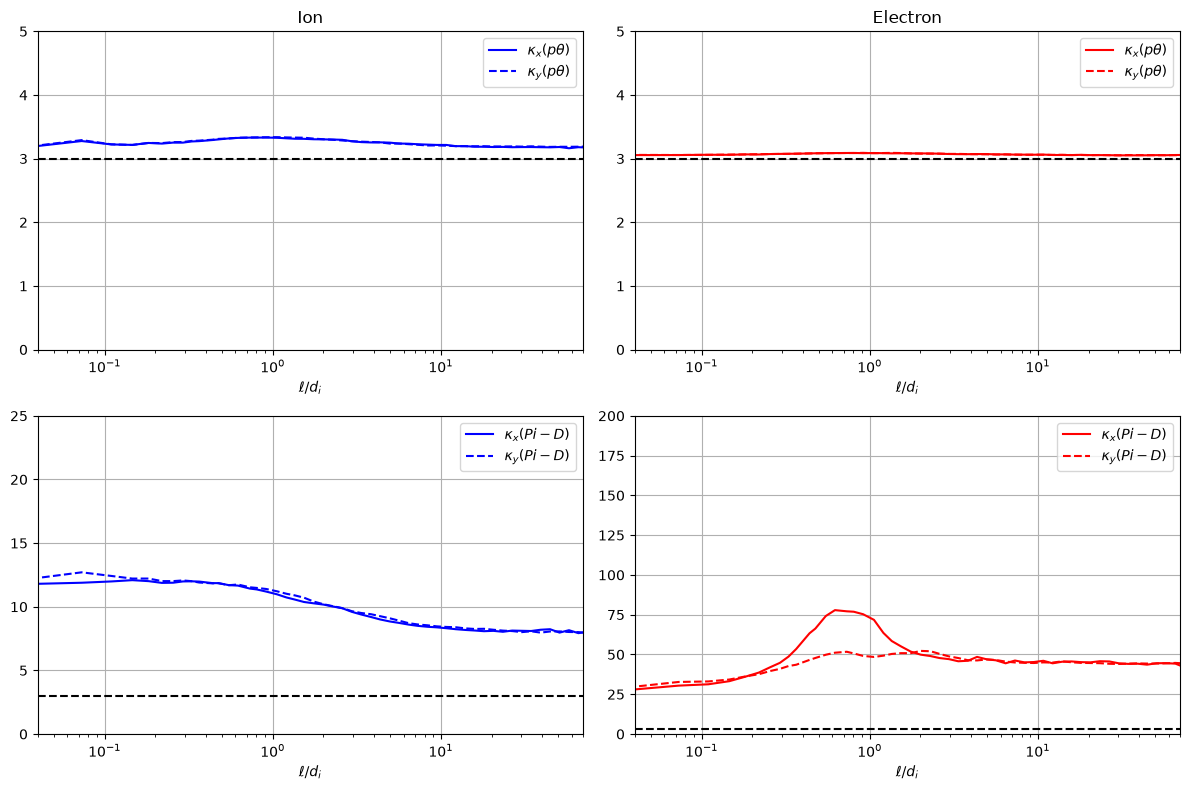

In [ ]:
fig, ax = plt.subplots(2,2, figsize = (12, 8))




ax[0,1].set_title("Electron")
ax[0,0].set_title("Ion")


ax[0,1].plot(K_e.ell, K_e.ptheta_x, ls = '-', c = 'red', label= r"$\kappa_{x}(p \theta)$")
ax[0,1].plot(K_e.ell, K_e.ptheta_y, ls = '--', c = 'red', label=r"$\kappa_{y}(p \theta)$")

ax[0,0].plot(K_i.ell, K_i.ptheta_x, ls = '-', c = 'blue', label= r"$\kappa_{x}(p \theta)$")
ax[0,0].plot(K_i.ell, K_i.ptheta_y, ls = '--', c = 'blue', label=r"$\kappa_{y}(p \theta)$")

ax[1,1].plot(K_e.ell, K_e.PiD_x, ls = '-', c = 'red', label= r"$\kappa_{x}( Pi\text{-}D)$")
ax[1,1].plot(K_e.ell, K_e.PiD_y, ls = '--', c = 'red', label=r"$\kappa_{y}( Pi\text{-}D)$")

ax[1,0].plot(K_i.ell, K_i.PiD_x, ls = '-', c = 'blue', label= r"$\kappa_{x}(Pi\text{-}D)$")
ax[1,0].plot(K_i.ell, K_i.PiD_y, ls = '--', c = 'blue', label=r"$\kappa_{y}(Pi\text{-}D)$")


ax[1,0].set_ylim(0, 25)
ax[1,1].set_ylim(0, 200)


for i in range(2):
    for j in range(2):
        ax[i,j].grid(True)


for i in range(2):
        ax[0,i].axhline(3, color="k", linestyle="--")
        ax[0,i].set(xscale="log", xlabel=r"$\ell/d_i$")
        ax[0,i].set_ylim(0, 5)
        ax[0,i].set_xlim(4e-2, 7e1)
        ax[0,i].legend()

for i in range(2):
        ax[1,i].axhline(3, color="k", linestyle="--")
        ax[1,i].set(xscale="log", xlabel=r"$\ell/d_i$")
        ax[1,i].set_xlim(4e-2, 7e1)
        ax[1,i].legend(loc='upper right')
fig.tight_layout()
fig.savefig("../fig/SD_kurtosis.png")